---
title: "Selección de variables con Ridge y Lasso: un caso de política pública"
format:
  html:
    code-fold: false
---

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aavelozb/aavelozb.github.io/blob/main/est852/notebooks/04-seleccion-variables-gc.ipynb)

Ejemplo de la clase **Regression with Regularization: Ridge and Lasso**.

Contenido

1. Un problema de política pública y generación de datos.
2. Exploración de un conjunto mixto.
3. Preprocesamiento con `ColumnTransformer`, y por qué va dentro del `Pipeline`.
4. Mínimos cuadrados y su inestabilidad.
5. Ridge, trayectoria de coeficientes y elección de $\lambda$ por validación cruzada.
6. Lasso, selección de variables y regla de un error estándar.
7. Comparación de lo seleccionado contra la verdad conocida.
8. Variables categóricas.
9. Elastic net y los predictores correlacionados.
10. Estabilidad de la selección por remuestreo.
11. Desempeño fuera de muestra.
12. Lectura de los resultados para política pública.

**Notación.** $\mathbf{X} \in \mathbb{R}^{N\times p}$ es la matriz de diseño,
$\mathbf{y} \in \mathbb{R}^{N}$ la respuesta, $\beta$ los coeficientes y $\lambda$ el
parámetro de regularización. En `scikit-learn` ese parámetro se llama `alpha`.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 110)

SEMILLA = 852
rng = np.random.default_rng(SEMILLA)

## 1. El problema

Un servicio local de educación dispone de un puntaje promedio de aprendizaje por establecimiento y de un registro administrativo con varias decenas de indicadores de la escuela y de su comuna. La pregunta es la habitual en política pública, **qué factores acompañan sistemáticamente al rendimiento y cuáles son ruido**, para concentrar el diagnóstico en algunas variables que se puedan monitorear.

El registro tiene tres rasgos que hacen incómodo el ajuste por mínimos cuadrados.

- Hay muchas más variables candidatas que ideas sustantivas, y buena parte son indicadores de gestión sin relación con el aprendizaje.
- Varias variables miden lo mismo por distintas vías. El ingreso mediano del hogar, la tasa de pobreza comunal y el acceso a internet son tres lecturas del mismo nivel socioeconómico.
- Hay variables categóricas con varios niveles, como la macrozona o la dependencia administrativa del establecimiento, que se convierten en varias columnas cada una.

Los datos son **simulados**. Esto permite evaluar un procedimiento de selección, porque sólo con datos simulados se conoce el conjunto de variables verdaderamente relevantes y se puede contar cuántas recupera cada
método. Las escalas y las relaciones se eligieron para que se parezcan a las de un registro educativo real.

## 2. Los datos

La generación sigue una estructura plausible. Un nivel socioeconómico latente por establecimiento condiciona la composición de su matrícula, el ingreso de las familias, la ruralidad y la dependencia administrativa. El puntaje depende de un subconjunto pequeño de esas variables más un término de error.

In [21]:
N = 1200

# Nivel socioeconómico latente (no observado)
base_macro = {"Norte": -0.05, "Centro": -0.10, "RM": 0.25, "Sur": -0.20, "Austral": -0.05}
macrozona = rng.choice(list(base_macro), size=N, p=[0.12, 0.24, 0.34, 0.22, 0.08])
nse = np.array([base_macro[m] for m in macrozona]) + rng.normal(0, 1, N)

# Variables categóricas
p_rural = 1 / (1 + np.exp(1.9 + 1.2 * nse))
zona = np.where(rng.random(N) < p_rural, "Rural", "Urbano")

util = np.column_stack([np.zeros(N), 0.8 + 0.5 * nse, -2.4 + 1.7 * nse])  # Mun, PS, PP
prob = np.exp(util) / np.exp(util).sum(1, keepdims=True)
niveles_dep = np.array(["Municipal", "Part. subvencionado", "Part. pagado"])
dependencia = niveles_dep[[rng.choice(3, p=fila) for fila in prob]]

In [22]:
# Variables numéricas
ingreso_mediano   = np.exp(12.9 + 0.42 * nse + rng.normal(0, 0.18, N))          # CLP
escolaridad_madre = np.clip(10.6 + 1.5 * nse + rng.normal(0, 1.1, N), 4, 21)    # años
ratio_alumno_doc  = np.clip(22 - 2.5 * nse + rng.normal(0, 3.0, N), 6, 45)
asistencia        = np.clip(92 - 2.0 * (zona == "Rural") + 1.2 * nse
                            + rng.normal(0, 2.5, N), 60, 100)                   # %
gasto_educ_pc     = np.exp(5.9 - 0.25 * nse + rng.normal(0, 0.30, N))           # miles CLP

# Variables numéricas redundantes (miden el mismo NSE)
pobreza_comunal   = np.clip(14 - 5.5 * nse + rng.normal(0, 2.2, N), 0.4, 60)    # %
acceso_internet   = 100 / (1 + np.exp(-(1.1 + 0.85 * nse + rng.normal(0, 0.35, N))))

# Indicadores administrativos sin efecto sobre el aprendizaje
ruido = {
    "antiguedad_edificio":   np.clip(rng.gamma(4, 6, N), 1, 90),
    "superficie_terreno_m2": np.exp(8.0 + 0.5 * rng.normal(0, 1, N)),
    "dias_habiles_ano":      np.round(rng.normal(188, 4, N)),
    "n_funcionarios_admin":  np.clip(rng.poisson(7, N), 1, None),
    "rotacion_admin":        np.clip(rng.beta(2, 8, N) * 100, 0, 100),
    "edad_media_docentes":   np.clip(rng.normal(44, 6, N), 25, 68),
    "n_reuniones_consejo":   np.clip(rng.poisson(9, N), 0, None),
    "distancia_capital_km":  np.exp(3.0 + 0.9 * rng.normal(0, 1, N)),
    "presupuesto_mantencion": np.exp(8.6 + 0.45 * rng.normal(0, 1, N)),
    "n_tramites_digitales":  np.clip(rng.poisson(15, N), 0, None),
    "indice_conectividad":   np.clip(rng.normal(50, 12, N), 0, 100),
    "matricula_total":       np.exp(5.4 + 0.35 * (zona == "Urbano") + rng.normal(0, 0.5, N)),
}

Variable de interés para la política: Participación en un **programa de apoyo socioeducativo**. 

Su asignación no es aleatoria, el programa se focaliza en las comunas más pobres, que son justamente las de menor puntaje. Esa focalización es lo que más adelante obliga a separar predicción de efecto causal.

In [23]:
p_programa = 1 / (1 + np.exp(-(-0.5 + 0.11 * (pobreza_comunal - 14))))
programa_apoyo = np.where(rng.random(N) < p_programa, "Si", "No")

def z(v):
    v = np.asarray(v, dtype=float)
    return (v - v.mean()) / v.std()

# Modelo verdadero
efecto_dep   = {"Municipal": 0.0, "Part. subvencionado": 6.0, "Part. pagado": 18.0}
efecto_macro = {"Norte": 0.0, "Centro": 1.5, "RM": 3.0, "Sur": -1.0, "Austral": -2.0}

puntaje = (250.0
           + 12.0 * z(escolaridad_madre)
           +  9.0 * z(np.log(ingreso_mediano))
           -  6.0 * z(ratio_alumno_doc)
           +  7.5 * z(asistencia)
           +  3.0 * z(np.log(gasto_educ_pc))
           +  2.5 * z(acceso_internet)
           + np.array([efecto_dep[d] for d in dependencia])
           + np.array([efecto_macro[m] for m in macrozona])
           - 4.0 * (zona == "Rural")
           + 3.5 * (programa_apoyo == "Si")
           + rng.normal(0, 24, N))

In [24]:
datos = pd.DataFrame({
    "puntaje": puntaje,
    "macrozona": macrozona, "zona": zona, "dependencia": dependencia,
    "programa_apoyo": programa_apoyo,
    "ingreso_mediano": ingreso_mediano, "escolaridad_madre": escolaridad_madre,
    "ratio_alumno_doc": ratio_alumno_doc, "asistencia": asistencia,
    "gasto_educ_pc": gasto_educ_pc, "pobreza_comunal": pobreza_comunal,
    "acceso_internet": acceso_internet, **ruido,
})

# Las variables monetarias y de tamaño son fuertemente asimétricas. Entran en
# logaritmo, que es la escala en que su relación con el puntaje es aproximadamente
# lineal, y es también la escala en que se generaron.
ASIMETRICAS = ["ingreso_mediano", "gasto_educ_pc", "superficie_terreno_m2",
               "presupuesto_mantencion", "distancia_capital_km", "matricula_total"]
datos[ASIMETRICAS] = np.log(datos[ASIMETRICAS])
datos = datos.rename(columns={c: "log_" + c for c in ASIMETRICAS})

# variables con coeficiente verdadero distinto de cero
VERDADERAS = {"escolaridad_madre", "log_ingreso_mediano", "ratio_alumno_doc",
              "asistencia", "log_gasto_educ_pc", "acceso_internet",
              "dependencia", "macrozona", "zona", "programa_apoyo"}

VARS_CAT = ["macrozona", "zona", "dependencia", "programa_apoyo"]
VARS_NUM = [c for c in datos.columns if c not in VARS_CAT + ["puntaje"]]

print(f"{datos.shape[0]} establecimientos, {len(VARS_NUM)} numéricas, "f"{len(VARS_CAT)} categóricas")
datos.head(4)

1200 establecimientos, 19 numéricas, 4 categóricas


,puntaje,macrozona,zona,dependencia,programa_apoyo,log_ingreso_mediano,escolaridad_madre,ratio_alumno_doc,asistencia,log_gasto_educ_pc,...,dias_habiles_ano,n_funcionarios_admin,rotacion_admin,edad_media_docentes,n_reuniones_consejo,log_distancia_capital_km,log_presupuesto_mantencion,n_tramites_digitales,indice_conectividad,log_matricula_total
0,313.871745,RM,Urbano,Part. pagado,Si,13.411845,13.029179,20.598364,93.655203,5.403681,...,183.0,3,9.507244,45.560282,8,2.164955,8.703562,18,45.207065,6.156789
1,257.703776,Austral,Rural,Part. pagado,Si,12.813695,10.590823,17.282254,91.892508,5.489571,...,185.0,15,16.184686,51.682567,9,3.854188,8.260446,14,56.113878,5.043001
2,266.280086,Austral,Urbano,Part. subvencionado,Si,12.900225,10.861576,18.871940,87.127273,5.680313,...,191.0,5,1.452469,40.730310,8,2.077318,8.585049,26,58.895219,6.174090
3,276.719949,Sur,Urbano,Part. subvencionado,No,13.322575,12.858258,20.039422,90.421043,5.974324,...,182.0,5,30.846908,41.518990,9,3.415349,8.445762,18,51.005614,6.026948


In [25]:
print("variables categóricas y sus niveles")
for c in VARS_CAT:
    print(f"  {c:16s}", dict(datos[c].value_counts()))
print()
datos[["puntaje", "log_ingreso_mediano", "escolaridad_madre", "asistencia",
       "pobreza_comunal", "acceso_internet"]].describe().round(2)

variables categóricas y sus niveles
  macrozona        {'RM': np.int64(370), 'Centro': np.int64(288), 'Sur': np.int64(282), 'Norte': np.int64(153), 'Austral': np.int64(107)}
  zona             {'Urbano': np.int64(970), 'Rural': np.int64(230)}
  dependencia      {'Part. subvencionado': np.int64(737), 'Municipal': np.int64(383), 'Part. pagado': np.int64(80)}
  programa_apoyo   {'No': np.int64(704), 'Si': np.int64(496)}



,puntaje,log_ingreso_mediano,escolaridad_madre,asistencia,pobreza_comunal,acceso_internet
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,257.22,12.90,10.58,91.63,14.02,71.48
std,39.38,0.46,1.89,2.97,5.89,16.53
min,130.66,11.46,4.46,81.38,0.40,5.58
25%,230.63,12.57,9.30,89.75,9.79,60.55
50%,257.73,12.90,10.57,91.73,14.16,74.60
75%,283.93,13.22,11.81,93.65,18.29,85.02
max,393.46,14.42,16.97,100.00,32.79,98.83


Antes de tocar los datos se separa un conjunto de prueba. Todo lo que sigue, incluida la
elección de $\lambda$ y la decisión sobre qué variables conservar, ocurre dentro del
conjunto de entrenamiento. El de prueba se abre una sola vez al final.

In [26]:
from sklearn.model_selection import train_test_split

X = datos.drop(columns="puntaje")
y = datos["puntaje"].to_numpy()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)
print("entrenamiento:", X_tr.shape, " prueba:", X_te.shape)

entrenamiento: (900, 23)  prueba: (300, 23)


## 3. Exploración

Dos figuras bastan para ver la estructura del problema. La primera muestra el puntaje según
las categóricas, la segunda muestra que varias numéricas son casi la misma variable.

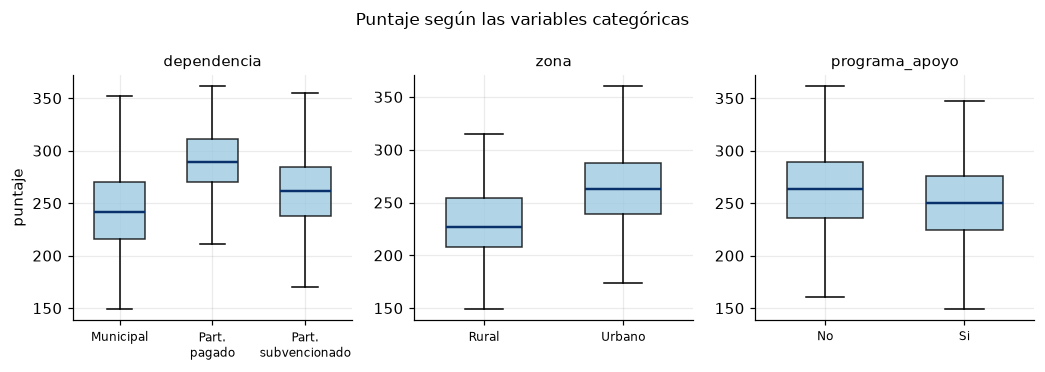

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.4))

for ax, var in zip(axes, ["dependencia", "zona", "programa_apoyo"]):
    niveles = sorted(X_tr[var].unique())
    partes = [y_tr[X_tr[var] == g] for g in niveles]
    bp = ax.boxplot(partes, tick_labels=[g.replace(". ", ".\n") for g in niveles],
                    widths=0.55, patch_artist=True, showfliers=False)
    for caja in bp["boxes"]:
        caja.set(facecolor="#9ecae1", alpha=0.8)
    for med in bp["medians"]:
        med.set(color="#08306b", lw=1.6)
    ax.set_title(var, fontsize=10)
    ax.tick_params(axis="x", labelsize=8)

axes[0].set_ylabel("puntaje")
fig.suptitle("Puntaje según las variables categóricas", fontsize=11)
fig.tight_layout(); plt.show()

La dependencia separa claramente. La zona algo menos. Y el programa de apoyo aparece asociado a **peor** puntaje, pese a que en el modelo generador su coeficiente es positivo. Es el efecto de la focalización, el programa llega donde el puntaje ya era bajo. Ninguna
regresión lo va a arreglar por sí sola.

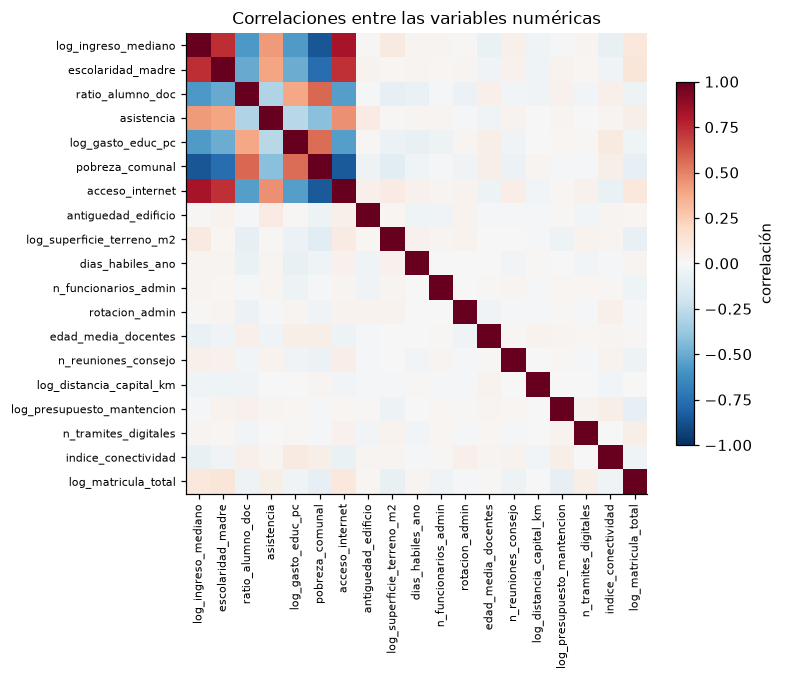

pares más correlacionados
 log_ingreso_mediano  pobreza_comunal        0.857
pobreza_comunal      log_ingreso_mediano    0.857
acceso_internet      pobreza_comunal        0.841
pobreza_comunal      acceso_internet        0.841
acceso_internet      log_ingreso_mediano    0.821
log_ingreso_mediano  acceso_internet        0.821
dtype: float64


In [28]:
corr = X_tr[VARS_NUM].corr().to_numpy()

fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARS_NUM)), VARS_NUM, rotation=90, fontsize=7)
ax.set_yticks(range(len(VARS_NUM)), VARS_NUM, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="correlación")
ax.set_title("Correlaciones entre las variables numéricas", fontsize=11)
fig.tight_layout(); plt.show()

pares = (X_tr[VARS_NUM].corr()
         .where(~np.eye(len(VARS_NUM), dtype=bool)).stack()
         .abs().sort_values(ascending=False))
print("pares más correlacionados\n", pares.head(6).round(3))

El bloque socioeconómico salta a la vista. Ingreso, pobreza y acceso a internet forman un grupo con correlaciones por sobre 0.7 en valor absoluto. Ese es exactamente el escenario donde mínimos cuadrados reparte coeficientes grandes y de signo arbitrario entre variables que dicen lo mismo, y donde ridge y lasso se comportan de forma distinta.

## 4. Preprocesamiento

Hay que resolver dos cosas antes de penalizar.

**Las categóricas se codifican.** Cada variable con $K$ niveles se convierte en $K-1$
columnas indicadoras, dejando un nivel como referencia que queda absorbido por el
intercepto.

**Todas las columnas se llevan a escala común.** Ridge y lasso suman coeficientes a través
de predictores, de modo que una variable medida en pesos y otra en años producen
penalizaciones incomparables. Se estandariza también las columnas indicadoras, para que la
penalización no dependa de la frecuencia del nivel. Es una convención discutible, y en la
sección 8 se ve qué se paga por ella.

El punto operativo es que el preprocesamiento va **dentro** del `Pipeline`. Si se
estandariza el conjunto completo antes de la validación cruzada, cada pliegue de validación
contribuye con su media y su varianza al ajuste, y la estimación del error sale optimista.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def hacer_preproc(cat=VARS_CAT, num=VARS_NUM, categorias="auto"):
    return ColumnTransformer([
        ("num", "passthrough", num),
        ("cat", OneHotEncoder(drop="first", sparse_output=False,
                              categories=categorias), cat),
    ])

def hacer_pipeline(modelo, categorias="auto"):
    return Pipeline([("prep", hacer_preproc(categorias=categorias)),
                     ("esc", StandardScaler()),
                     ("modelo", modelo)])

prep = hacer_preproc().fit(X_tr)
nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print(f"{len(VARS_NUM)} numéricas + {len(VARS_CAT)} categóricas  ->  "
      f"{len(nombres)} columnas de diseño")
print(nombres[-8:])

19 numéricas + 4 categóricas  ->  27 columnas de diseño
['macrozona_Centro', 'macrozona_Norte', 'macrozona_RM', 'macrozona_Sur', 'zona_Urbano', 'dependencia_Part. pagado', 'dependencia_Part. subvencionado', 'programa_apoyo_Si']


Para dibujar las trayectorias de coeficientes conviene tener la matriz de diseño ya
transformada y la respuesta centrada, igual que en el cuaderno 02. Esta transformación única
se usa solo para las figuras, la elección de $\lambda$ sigue haciéndose con el `Pipeline`
completo dentro de la validación cruzada.

In [30]:
esc = StandardScaler().fit(prep.transform(X_tr))
Xd_tr = esc.transform(prep.transform(X_tr))
Xd_te = esc.transform(prep.transform(X_te))
yc_tr = y_tr - y_tr.mean()

# de cada columna de diseño a la variable original que la originó
def variable_origen(col):
    for v in VARS_CAT:
        if col.startswith(v + "_"):
            return v
    return col

ORIGEN = np.array([variable_origen(c) for c in nombres])
print("Xd_tr:", Xd_tr.shape)

Xd_tr: (900, 27)


## 5. Mínimos cuadrados como punto de partida

$$\widehat{\beta}^{\,\mathrm{ls}} = (\mathbf{X}^{\top}\mathbf{X})^{-1}\mathbf{X}^{\top}\mathbf{y}$$

Con 900 observaciones y 27 columnas de diseño la solución existe y no hay ningún
problema numérico aparente. El
problema es otro, los coeficientes del bloque socioeconómico son inestables. Se ve
remuestreando el conjunto de entrenamiento y observando cuánto se mueve cada coeficiente.

In [31]:
from sklearn.linear_model import LinearRegression

d = np.linalg.svd(Xd_tr, compute_uv=False)
print(f"número de condición de X   : {d[0] / d[-1]:7.1f}")
print(f"número de condición de X'X : {(d[0] / d[-1]) ** 2:7.1f}")

ols = LinearRegression().fit(Xd_tr, yc_tr)

B = np.empty((400, Xd_tr.shape[1]))
idx = np.arange(len(yc_tr))
for b in range(400):
    s = rng.choice(idx, size=len(idx), replace=True)
    B[b] = LinearRegression().fit(Xd_tr[s], yc_tr[s]).coef_

resumen = pd.DataFrame({"beta_ls": ols.coef_,
                        "sd_bootstrap": B.std(0)}, index=nombres)
resumen["|t| aprox"] = (resumen.beta_ls / resumen.sd_bootstrap).abs()
print()
print(resumen.loc[["log_ingreso_mediano", "pobreza_comunal", "acceso_internet",
                   "escolaridad_madre", "asistencia"]].round(2))

número de condición de X   :     6.7
número de condición de X'X :    45.5

                     beta_ls  sd_bootstrap  |t| aprox
log_ingreso_mediano     6.31          1.74       3.64
pobreza_comunal         0.32          1.77       0.18
acceso_internet         3.57          1.92       1.86
escolaridad_madre      12.49          1.45       8.61
asistencia              8.57          0.99       8.69


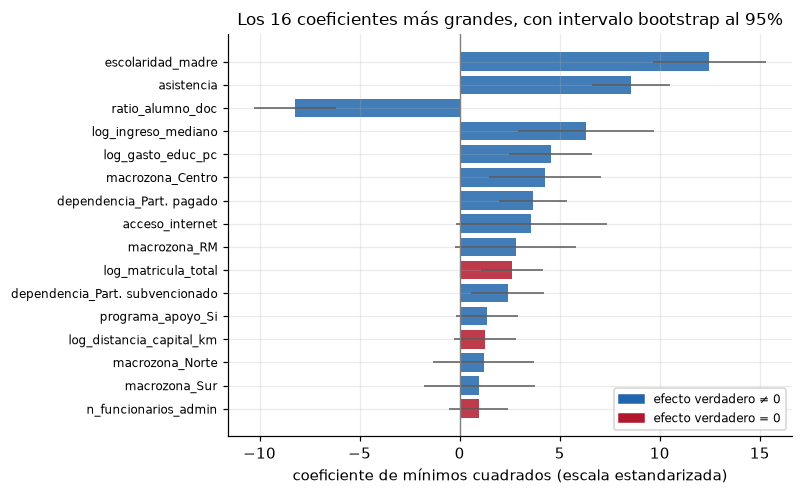

In [32]:
orden = np.argsort(np.abs(ols.coef_))[::-1][:16]
colores = ["#2166ac" if ORIGEN[j] in VERDADERAS else "#b2182b" for j in orden]

fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.barh(range(len(orden)), ols.coef_[orden], xerr=1.96 * B.std(0)[orden],
        color=colores, alpha=0.85, error_kw=dict(lw=1, ecolor="0.35"))
ax.set_yticks(range(len(orden)), [nombres[j] for j in orden], fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="gray", lw=0.9)
ax.set_xlabel("coeficiente de mínimos cuadrados (escala estandarizada)")
ax.set_title("Los 16 coeficientes más grandes, con intervalo bootstrap al 95%",
             fontsize=11)
ax.legend(handles=[Patch(color="#2166ac", label="efecto verdadero ≠ 0"),
                   Patch(color="#b2182b", label="efecto verdadero = 0")],
          fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

Mínimos cuadrados no deja ningún coeficiente en cero, así que **no selecciona nada**. Deja
27 coeficientes distintos de cero, entre ellos los de todos los indicadores
administrativos, y reparte el efecto socioeconómico entre tres variables
correlacionadas con intervalos tan anchos que dos de ellos cruzan el cero. Un informe construido sobre esta tabla mencionaría variables que no
tienen efecto alguno.

## 6. Ridge

$$\widehat{\beta}^{\,\mathrm{ridge}} = \arg\min_{\beta}\;
\lVert \mathbf{y}-\mathbf{X}\beta \rVert^2 + \lambda \lVert \beta \rVert_2^2$$

La penalización cuadrática encoge todos los coeficientes hacia cero de manera continua, sin
anular ninguno. Con predictores correlacionados los **reparte** entre ellos, que es lo
sensato cuando se busca predecir, y lo inservible cuando se busca una lista corta de
variables.

In [33]:
lams = np.logspace(-1, 5, 120)
p_d = Xd_tr.shape[1]
B_ridge = np.array([np.linalg.solve(Xd_tr.T @ Xd_tr + l * np.eye(p_d), Xd_tr.T @ yc_tr)
                    for l in lams])

# grados de libertad efectivos: df(lambda) = sum_j d_j^2 / (d_j^2 + lambda)
df_ridge = np.array([(d ** 2 / (d ** 2 + l)).sum() for l in lams])

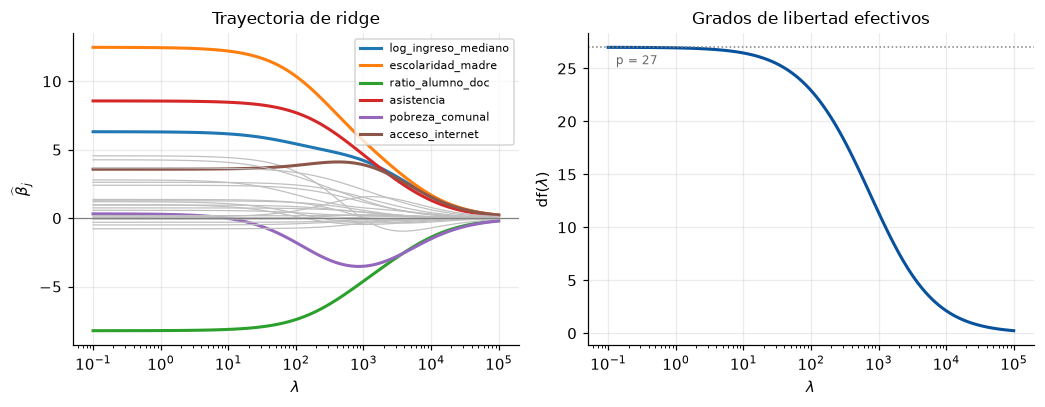

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))

destacadas = ["log_ingreso_mediano", "pobreza_comunal", "acceso_internet",
              "escolaridad_madre", "asistencia", "ratio_alumno_doc"]
for j, nom in enumerate(nombres):
    if nom in destacadas:
        axes[0].semilogx(lams, B_ridge[:, j], lw=2, label=nom)
    else:
        axes[0].semilogx(lams, B_ridge[:, j], lw=0.8, color="0.75")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_xlabel(r"$\lambda$"); axes[0].set_ylabel(r"$\widehat{\beta}_j$")
axes[0].set_title("Trayectoria de ridge", fontsize=11)
axes[0].legend(fontsize=7, ncol=1)

axes[1].semilogx(lams, df_ridge, color="#08519c", lw=2)
axes[1].axhline(p_d, color="gray", ls=":", lw=1)
axes[1].text(lams[0] * 1.3, p_d - 1.6, f"p = {p_d}", fontsize=8, color="0.4")
axes[1].set_xlabel(r"$\lambda$"); axes[1].set_ylabel(r"df($\lambda$)")
axes[1].set_title("Grados de libertad efectivos", fontsize=11)

fig.tight_layout(); plt.show()

Ninguna curva toca el cero. Los grados de libertad efectivos
$\mathrm{df}(\lambda)=\sum_j d_j^2/(d_j^2+\lambda)$ bajan de forma continua desde $p$ hasta
cero, y son la manera correcta de decir cuánta complejidad queda tras penalizar.

### Elección de $\lambda$

La rejilla se recorre con validación cruzada de cinco pliegues sobre el `Pipeline`
completo, de modo que la estandarización se reajusta en cada pliegue.

In [35]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=1)

rejilla_ridge = np.logspace(-1, 5, 60)
bus_ridge = GridSearchCV(hacer_pipeline(Ridge()),
                         {"modelo__alpha": rejilla_ridge},
                         scoring="neg_mean_squared_error", cv=kf, n_jobs=-1)
bus_ridge.fit(X_tr, y_tr)

mse_r = -bus_ridge.cv_results_["mean_test_score"]
se_r = bus_ridge.cv_results_["std_test_score"] / np.sqrt(kf.get_n_splits())
lam_r_min = bus_ridge.best_params_["modelo__alpha"]

print(f"lambda óptimo (ridge): {lam_r_min:.2f}   ECM de CV: {mse_r.min():.1f}")

lambda óptimo (ridge): 27.59   ECM de CV: 622.9


## 7. Lasso

$$\widehat{\beta}^{\,\mathrm{lasso}} = \arg\min_{\beta}\;
\tfrac{1}{2N}\lVert \mathbf{y}-\mathbf{X}\beta \rVert^2 + \lambda \lVert \beta \rVert_1$$

La penalización en valor absoluto no es diferenciable en el origen, y esa esquina es lo que
produce soluciones exactamente nulas. El lasso ajusta y selecciona en un solo paso.

Nótese el factor $1/(2N)$, que es la convención de `scikit-learn` y no la de ESL. Los
valores de `alpha` de `Lasso` no son comparables numéricamente con los de `Ridge`, ni con
los $\lambda$ de `glmnet` salvo por esa constante.

In [36]:
from sklearn.linear_model import Lasso, lasso_path

alphas_l, coefs_l, _ = lasso_path(Xd_tr, yc_tr, eps=1e-4, alphas=120)
n_activos = (np.abs(coefs_l) > 1e-8).sum(0)

# columnas de diseño cuyo coeficiente verdadero es distinto de cero
n_cols_verdaderas = int(np.isin(ORIGEN, list(VERDADERAS)).sum())
print(f"{n_cols_verdaderas} de las {len(nombres)} columnas provienen de una variable "
      "con efecto verdadero")

14 de las 27 columnas provienen de una variable con efecto verdadero


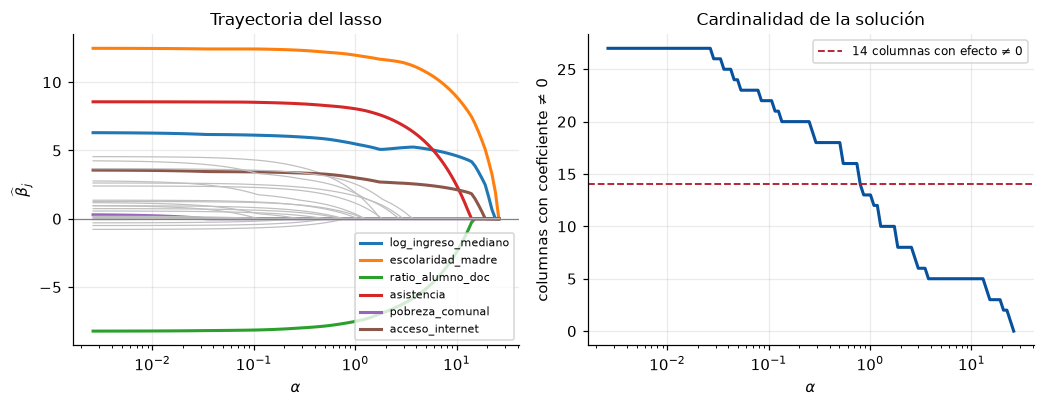

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8), sharex=True)

for j, nom in enumerate(nombres):
    estilo = dict(lw=2) if nom in destacadas else dict(lw=0.8, color="0.75")
    axes[0].semilogx(alphas_l, coefs_l[j], label=nom if nom in destacadas else None,
                     **estilo)
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_xlabel(r"$\alpha$"); axes[0].set_ylabel(r"$\widehat{\beta}_j$")
axes[0].set_title("Trayectoria del lasso", fontsize=11)
axes[0].legend(fontsize=7)

axes[1].semilogx(alphas_l, n_activos, color="#08519c", lw=2)
axes[1].axhline(n_cols_verdaderas, color="#b2182b", ls="--", lw=1.2,
                label=f"{n_cols_verdaderas} columnas con efecto ≠ 0")
axes[1].set_xlabel(r"$\alpha$"); axes[1].set_ylabel("columnas con coeficiente ≠ 0")
axes[1].set_title("Cardinalidad de la solución", fontsize=11)
axes[1].legend(fontsize=8)

fig.tight_layout(); plt.show()

Ahora sí hay curvas que llegan a cero y se quedan ahí. Leyendo de derecha a izquierda, cada
variable tiene un $\alpha$ de entrada, y el orden de entrada es una ordenación implícita
por importancia.

### Validación cruzada y regla de un error estándar

La curva de error de validación cruzada tiene un mínimo poco marcado, y esa planicie es
información. Cualquier $\alpha$ dentro de un error estándar del mínimo es indistinguible en
términos de error de predicción, así que se elige **el mayor de ellos**, que da el modelo
más pequeño. Es la regla de un error estándar, y en selección de variables importa más que
en predicción pura.

In [38]:
rejilla_lasso = np.logspace(-3, 1.2, 80)
bus_lasso = GridSearchCV(hacer_pipeline(Lasso(max_iter=50_000)),
                         {"modelo__alpha": rejilla_lasso},
                         scoring="neg_mean_squared_error", cv=kf, n_jobs=-1)
bus_lasso.fit(X_tr, y_tr)

mse_l = -bus_lasso.cv_results_["mean_test_score"]
se_l = bus_lasso.cv_results_["std_test_score"] / np.sqrt(kf.get_n_splits())

def regla_1se(rejilla, mse, se):
    # mayor alpha cuyo ECM de CV no supera el mínimo más un error estándar
    k = int(np.argmin(mse))
    umbral = mse[k] + se[k]
    return float(rejilla[mse <= umbral].max()), float(rejilla[k])

lam_l_1se, lam_l_min = regla_1se(rejilla_lasso, mse_l, se_l)
lam_r_1se, _ = regla_1se(rejilla_ridge, mse_r, se_r)

print(f"lasso  alpha_min = {lam_l_min:.4f}   alpha_1se = {lam_l_1se:.4f}")
print(f"ridge  alpha_min = {lam_r_min:.2f}     alpha_1se = {lam_r_1se:.2f}")

lasso  alpha_min = 0.4028   alpha_1se = 1.0725
ridge  alpha_min = 27.59     alpha_1se = 179.57


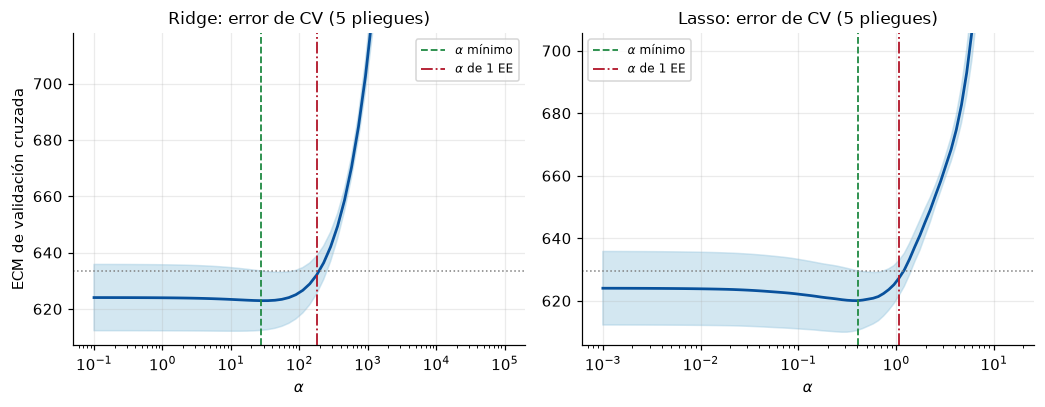

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))

for ax, rej, mse, se, lmin, l1se, tit in [
        (axes[0], rejilla_ridge, mse_r, se_r, lam_r_min, lam_r_1se, "Ridge"),
        (axes[1], rejilla_lasso, mse_l, se_l, lam_l_min, lam_l_1se, "Lasso")]:
    ax.fill_between(rej, mse - se, mse + se, color="#9ecae1", alpha=0.45)
    ax.semilogx(rej, mse, color="#08519c", lw=1.8)
    ax.axvline(lmin, color="#238b45", ls="--", lw=1.2, label=r"$\alpha$ mínimo")
    ax.axvline(l1se, color="#b2182b", ls="-.", lw=1.2, label=r"$\alpha$ de 1 EE")
    k = int(np.argmin(mse))
    ax.axhline(mse[k] + se[k], color="0.5", ls=":", lw=1)
    ax.set_ylim(mse.min() - 1.5 * se[k], mse.min() + 9 * se[k])  # zoom al mínimo
    ax.set_xlabel(r"$\alpha$"); ax.set_title(f"{tit}: error de CV (5 pliegues)",
                                             fontsize=11)
    ax.legend(fontsize=8)
axes[0].set_ylabel("ECM de validación cruzada")

fig.tight_layout(); plt.show()

In [40]:
lasso_min = hacer_pipeline(Lasso(alpha=lam_l_min, max_iter=50_000)).fit(X_tr, y_tr)
lasso_1se = hacer_pipeline(Lasso(alpha=lam_l_1se, max_iter=50_000)).fit(X_tr, y_tr)
ridge_min = hacer_pipeline(Ridge(alpha=lam_r_min)).fit(X_tr, y_tr)

def activas(pipe, tol=1e-8):
    c = pipe.named_steps["modelo"].coef_
    return {ORIGEN[j] for j in np.flatnonzero(np.abs(c) > tol)}

print(f"lasso (alpha mínimo): {(np.abs(lasso_min.named_steps['modelo'].coef_) > 1e-8).sum():2d}"
      f" columnas activas, {len(activas(lasso_min))} variables originales")
print(f"lasso (regla 1 EE)  : {(np.abs(lasso_1se.named_steps['modelo'].coef_) > 1e-8).sum():2d}"
      f" columnas activas, {len(activas(lasso_1se))} variables originales")
print(f"ridge               : {(np.abs(ridge_min.named_steps['modelo'].coef_) > 1e-8).sum():2d}"
      f" columnas activas (ridge nunca anula)")

lasso (alpha mínimo): 18 columnas activas, 16 variables originales
lasso (regla 1 EE)  : 12 columnas activas, 10 variables originales
ridge               : 27 columnas activas (ridge nunca anula)


## 8. Qué se seleccionó, comparado con la verdad

Con datos simulados se puede hacer lo que en un problema real es imposible, contar aciertos.
Una variable original cuenta como seleccionada si alguna de sus columnas de diseño tiene
coeficiente distinto de cero.

In [41]:
todas = set(VARS_NUM) | set(VARS_CAT)

def tabla_seleccion(sel, nombre):
    vp = len(sel & VERDADERAS)
    fp = len(sel - VERDADERAS)
    fn = len(VERDADERAS - sel)
    vn = len(todas - VERDADERAS - sel)
    return {"modelo": nombre, "seleccionadas": len(sel),
            "aciertos (VP)": vp, "falsos positivos": fp,
            "omitidas (FN)": fn, "descartes correctos": vn}

filas = [tabla_seleccion(todas, "mínimos cuadrados"),
         tabla_seleccion(todas, "ridge"),
         tabla_seleccion(activas(lasso_min), "lasso (alpha mínimo)"),
         tabla_seleccion(activas(lasso_1se), "lasso (regla 1 EE)")]
pd.DataFrame(filas).set_index("modelo")

,seleccionadas,aciertos (VP),falsos positivos,omitidas (FN),descartes correctos
modelo,,,,,
mínimos cuadrados,23,10,13,0,0
ridge,23,10,13,0,0
lasso (alpha mínimo),16,9,7,1,6
lasso (regla 1 EE),10,8,2,2,11


In [42]:
sel_1se = activas(lasso_1se)
print("verdaderas recuperadas :", sorted(sel_1se & VERDADERAS))
print("falsos positivos       :", sorted(sel_1se - VERDADERAS))
print("verdaderas omitidas    :", sorted(VERDADERAS - sel_1se))

verdaderas recuperadas : ['acceso_internet', 'asistencia', 'dependencia', 'escolaridad_madre', 'log_gasto_educ_pc', 'log_ingreso_mediano', 'macrozona', 'ratio_alumno_doc']
falsos positivos       : [np.str_('log_distancia_capital_km'), np.str_('log_matricula_total')]
verdaderas omitidas    : ['programa_apoyo', 'zona']


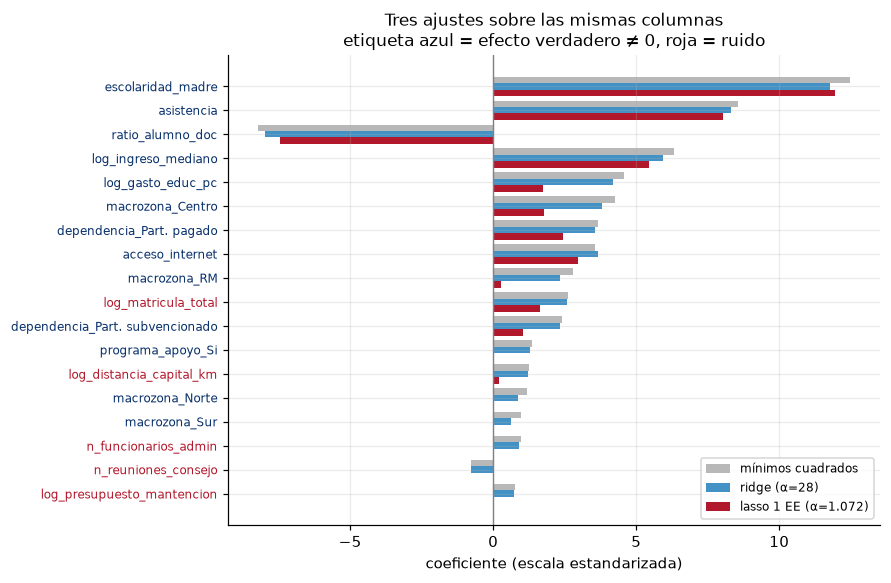

In [43]:
c_ols = ols.coef_
c_rid = ridge_min.named_steps["modelo"].coef_
c_las = lasso_1se.named_steps["modelo"].coef_

orden = np.argsort(np.abs(c_ols))[::-1][:18]
pos = np.arange(len(orden))
alto = 0.27

fig, ax = plt.subplots(figsize=(8.2, 5.4))
ax.barh(pos - alto, c_ols[orden], alto, label="mínimos cuadrados", color="0.72")
ax.barh(pos,        c_rid[orden], alto, label=f"ridge (α={lam_r_min:.0f})",
        color="#4292c6")
ax.barh(pos + alto, c_las[orden], alto, label=f"lasso 1 EE (α={lam_l_1se:.3f})",
        color="#b2182b")
ax.set_yticks(pos, [nombres[j] for j in orden], fontsize=8)
for j, tick in zip(orden, ax.get_yticklabels()):
    tick.set_color("#08306b" if ORIGEN[j] in VERDADERAS else "#b2182b")
ax.invert_yaxis(); ax.axvline(0, color="gray", lw=0.9)
ax.set_xlabel("coeficiente (escala estandarizada)")
ax.set_title("Tres ajustes sobre las mismas columnas\n"
             "etiqueta azul = efecto verdadero ≠ 0, roja = ruido", fontsize=11)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

Las barras grises nunca son cero. Las azules de ridge son grises encogidas, todas presentes
pero más pequeñas. Las rojas del lasso desaparecen en casi todo el bloque administrativo y
sobreviven concentradas en las etiquetas azules.

La tabla anterior muestra el precio de cada regla. Con el $\alpha$ del mínimo el lasso
retiene dieciséis variables y recupera casi todas las verdaderas, a cambio de arrastrar
media docena de indicadores administrativos. Con la regla de un error estándar quedan diez,
de las cuales ocho son verdaderas, y el costo son dos omisiones, `zona` y `programa_apoyo`,
cuyos efectos verdaderos son los más pequeños del modelo generador. **La regla de un error
estándar no es gratis**, compra parsimonia con sensibilidad, y qué se prefiere depende de
si el objetivo es no dejar fuera nada relevante o no incluir nada superfluo.

Los dos falsos positivos merecen lecturas distintas. `log_matricula_total` no es ruido puro,
es un sustituto de `zona`, porque los establecimientos urbanos son más grandes, así que el
lasso descartó la variable y se quedó con su sombra. `log_distancia_capital_km`, en cambio,
es un falso positivo genuino, y en la sección 11 se verá que el remuestreo lo delata.

Vale la pena mirar `pobreza_comunal`, cuyo coeficiente verdadero es cero. No es una variable
irrelevante en el sentido sustantivo, la pobreza importa muchísimo, sino que su información
ya está contenida en el ingreso mediano y en la escolaridad de la madre. El lasso la
descarta porque es redundante, no porque sea irrelevante, y esa distinción es la que hay que
explicitar en cualquier informe.

## 9. El problema específico de las variables categóricas

El lasso penaliza columna a columna, no variable a variable. Una categórica con cinco
niveles entra como cuatro columnas independientes, y nada impide que el método conserve dos
y elimine las otras dos. El resultado es un modelo donde la macrozona existe a medias, lo
cual es difícil de comunicar y depende de una decisión arbitraria previa, la elección del
nivel de referencia.

El experimento siguiente ajusta el mismo lasso, con el mismo $\alpha$, cambiando solo cuál
macrozona actúa como referencia.

In [44]:
niveles_macro = ["Norte", "Centro", "RM", "Sur", "Austral"]
otras_cat = {v: np.array(sorted(X_tr[v].unique())) for v in VARS_CAT if v != "macrozona"}

resultados_ref = {}
for ref in niveles_macro:
    orden_niveles = [ref] + [m for m in niveles_macro if m != ref]
    cats = [np.array(orden_niveles) if v == "macrozona" else otras_cat[v]
            for v in VARS_CAT]
    pipe = hacer_pipeline(Lasso(alpha=lam_l_1se, max_iter=50_000), categorias=cats)
    pipe.fit(X_tr, y_tr)
    nom_ref = [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    coef = pipe.named_steps["modelo"].coef_
    resultados_ref[ref] = {n: c for n, c in zip(nom_ref, coef)
                           if n.startswith("macrozona_")}

M = np.zeros((len(niveles_macro), len(niveles_macro)))
for i, ref in enumerate(niveles_macro):
    for j, niv in enumerate(niveles_macro):
        M[i, j] = resultados_ref[ref].get(f"macrozona_{niv}", np.nan)

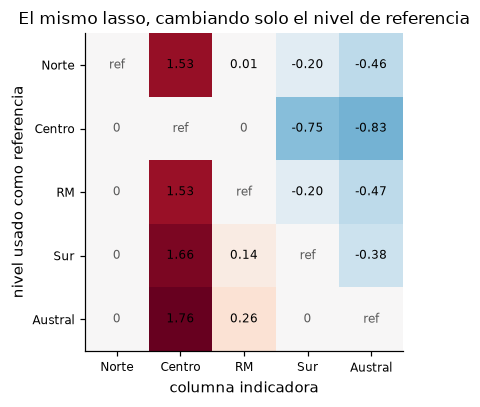

columnas de macrozona retenidas según la referencia
  referencia Norte    -> ['Centro', 'RM', 'Sur', 'Austral']
  referencia Centro   -> ['Sur', 'Austral']
  referencia RM       -> ['Centro', 'Sur', 'Austral']
  referencia Sur      -> ['Centro', 'RM', 'Austral']
  referencia Austral  -> ['Centro', 'RM']


In [45]:
fig, ax = plt.subplots(figsize=(6.6, 3.8))
im = ax.imshow(np.where(np.isnan(M), 0, M), cmap="RdBu_r",
               vmin=-np.nanmax(np.abs(M)), vmax=np.nanmax(np.abs(M)))
for i in range(len(niveles_macro)):
    for j in range(len(niveles_macro)):
        if np.isnan(M[i, j]):
            txt, col = "ref", "0.35"
        elif abs(M[i, j]) < 1e-8:
            txt, col = "0", "0.35"
        else:
            txt, col = f"{M[i, j]:.2f}", "black"
        ax.text(j, i, txt, ha="center", va="center", fontsize=8, color=col)
ax.set_xticks(range(5), niveles_macro, fontsize=8)
ax.set_yticks(range(5), niveles_macro, fontsize=8)
ax.set_xlabel("columna indicadora"); ax.set_ylabel("nivel usado como referencia")
ax.grid(False)
ax.set_title("El mismo lasso, cambiando solo el nivel de referencia", fontsize=11)
fig.tight_layout(); plt.show()

print("columnas de macrozona retenidas según la referencia")
for ref, dic in resultados_ref.items():
    vivas = [k.replace("macrozona_", "") for k, v in dic.items() if abs(v) > 1e-8]
    print(f"  referencia {ref:8s} -> {vivas if vivas else 'ninguna'}")

Cada fila retiene un subconjunto distinto. La decisión de codificación, que es puramente
administrativa, termina decidiendo qué macrozonas aparecen en el informe.

Hay tres salidas razonables.

- **Group lasso**, que penaliza el bloque completo de columnas de una categórica con una
  norma $\ell_2$, de modo que la variable entra o sale entera. No está en `scikit-learn`,
  pero sí en `group-lasso` y en `celer`.
- **Decidir a nivel de variable**, declarando seleccionada la categórica si sobrevive
  cualquiera de sus columnas. Es lo que se hizo en la sección 8, y basta cuando la pregunta
  es qué variables monitorear.
- **Reagrupar los niveles** antes de ajustar, cuando la teoría lo permite, por ejemplo
  colapsando macrozonas en zona centro contra resto.

Para la dependencia administrativa, que tiene un orden natural, el segundo camino funciona
sin conflicto.

In [46]:
coef_1se = pd.Series(lasso_1se.named_steps["modelo"].coef_, index=nombres)
print("columnas de variables categóricas en el lasso de 1 EE\n")
print(coef_1se[[n for n in nombres if variable_origen(n) in VARS_CAT]].round(3))

columnas de variables categóricas en el lasso de 1 EE

macrozona_Centro                   1.762
macrozona_Norte                   -0.000
macrozona_RM                       0.258
macrozona_Sur                     -0.000
zona_Urbano                        0.000
dependencia_Part. pagado           2.456
dependencia_Part. subvencionado    1.056
programa_apoyo_Si                  0.000
dtype: float64


## 10. Elastic net y los predictores correlacionados

El lasso, ante un grupo de variables muy correlacionadas, tiende a quedarse con una y anular
las demás, y cuál queda depende de fluctuaciones del muestreo. La red elástica combina las
dos penalizaciones,

$$\lambda\left[\tfrac{1-\rho}{2}\lVert\beta\rVert_2^2 + \rho\lVert\beta\rVert_1\right],$$

donde $\rho$ es `l1_ratio`. La parte $\ell_2$ produce el efecto de agrupamiento, las
variables correlacionadas entran o salen juntas y con coeficientes parecidos. Es la opción
razonable cuando interesa el grupo como bloque, por ejemplo cuando el bloque
socioeconómico completo es la unidad de interés de la política.

In [47]:
from sklearn.linear_model import ElasticNetCV

enet_cv = ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0],
                       alphas=60, cv=kf, max_iter=50_000, n_jobs=-1,
                       random_state=0)
enet = hacer_pipeline(enet_cv).fit(X_tr, y_tr)
m = enet.named_steps["modelo"]
print(f"l1_ratio elegido: {m.l1_ratio_:.2f}   alpha elegido: {m.alpha_:.4f}")
print(f"columnas activas: {(np.abs(m.coef_) > 1e-8).sum()} de {len(nombres)}")

l1_ratio elegido: 1.00   alpha elegido: 0.3856
columnas activas: 18 de 27


con l1_ratio = 0.3 la CV elige alpha = 0.0870, 25 columnas activas


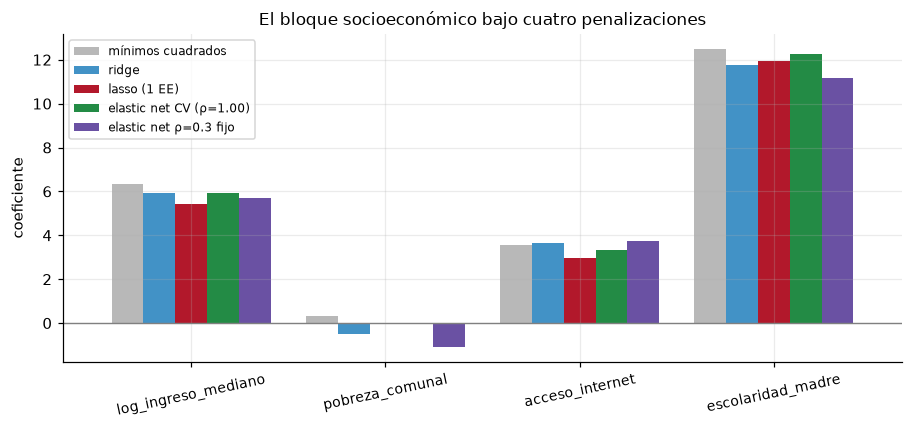

,mínimos cuadrados,ridge,lasso (1 EE),elastic net CV (ρ=1.00),elastic net ρ=0.3 fijo
log_ingreso_mediano,6.315,5.938,5.435,5.928,5.685
pobreza_comunal,0.315,-0.519,-0.000,-0.000,-1.084
acceso_internet,3.572,3.658,2.966,3.312,3.736
escolaridad_madre,12.486,11.770,11.943,12.278,11.176


In [48]:
grupo = ["log_ingreso_mediano", "pobreza_comunal", "acceso_internet",
         "escolaridad_madre"]
idx_g = [nombres.index(v) for v in grupo]

# la CV puede elegir l1_ratio = 1, es decir lasso puro. Para ver el efecto de
# agrupamiento se fija l1_ratio = 0.3 y se deja que la CV elija solo alpha.
enet_03 = hacer_pipeline(ElasticNetCV(l1_ratio=0.3, alphas=60, cv=kf,
                                      max_iter=50_000, n_jobs=-1,
                                      random_state=0)).fit(X_tr, y_tr)
c_e03 = enet_03.named_steps["modelo"].coef_
print(f"con l1_ratio = 0.3 la CV elige alpha = "
      f"{enet_03.named_steps['modelo'].alpha_:.4f}, "
      f"{(np.abs(c_e03) > 1e-8).sum()} columnas activas")

comparacion = pd.DataFrame({
    "mínimos cuadrados": c_ols[idx_g],
    "ridge": c_rid[idx_g],
    "lasso (1 EE)": c_las[idx_g],
    f"elastic net CV (ρ={m.l1_ratio_:.2f})": m.coef_[idx_g],
    "elastic net ρ=0.3 fijo": c_e03[idx_g],
}, index=grupo)

fig, ax = plt.subplots(figsize=(8.4, 4.0))
comparacion.plot.bar(ax=ax, color=["0.72", "#4292c6", "#b2182b", "#238b45",
                                  "#6a51a3"], width=0.82, legend=True)
ax.axhline(0, color="gray", lw=0.9)
ax.set_ylabel("coeficiente"); ax.tick_params(axis="x", rotation=12, labelsize=9)
ax.set_title("El bloque socioeconómico bajo cuatro penalizaciones", fontsize=11)
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

comparacion.round(3)

Conviene notar qué eligió la validación cruzada. Con la rejilla de `l1_ratio` libre terminó
en el extremo del lasso puro, porque para **predecir** no hace falta repartir el efecto
entre variables redundantes, basta con quedarse con una. El agrupamiento es una propiedad
que se pide por razones de interpretación, no porque mejore el error, y por eso la segunda
red elástica lleva el `l1_ratio` fijado por decisión del analista.

Con esa restricción se ve el contraste completo. Mínimos cuadrados reparte con signos que no
resisten el remuestreo, ridge reparte de forma suave, el lasso concentra en dos variables y
anula `pobreza_comunal`, y la red elástica con parte $\ell_2$ apreciable vuelve a admitir a
las cuatro, devolviéndole a la pobreza un coeficiente no nulo. Si el informe habla de un bloque socioeconómico, la última es la
representación honesta. Si el informe necesita un indicador único para monitorear, la
tercera.

## 11. Estabilidad de la selección

Un solo ajuste del lasso entrega una lista de variables, pero no dice cuán reproducible es
esa lista. La forma barata de averiguarlo es remuestrear el conjunto de entrenamiento,
reajustar y contar con qué frecuencia sobrevive cada variable. Es la idea de la *stability
selection* de Meinshausen y Bühlmann, en su versión mínima.

Las variables que aparecen en más del 80% de los remuestreos se pueden reportar con
confianza. Las que aparecen en torno al 50% son precisamente aquellas sobre las cuales el
método no tiene una opinión firme, y reportarlas como hallazgo sería sobreinterpretar.

In [49]:
B_REP = 300
conteo = pd.Series(0, index=sorted(todas), dtype=int)
idx = np.arange(len(y_tr))

for b in range(B_REP):
    s = rng.choice(idx, size=len(idx), replace=True)
    pipe_b = hacer_pipeline(Lasso(alpha=lam_l_1se, max_iter=20_000))
    pipe_b.fit(X_tr.iloc[s], y_tr[s])
    for v in activas(pipe_b):
        conteo[v] += 1

frec = (conteo / B_REP).sort_values(ascending=False)

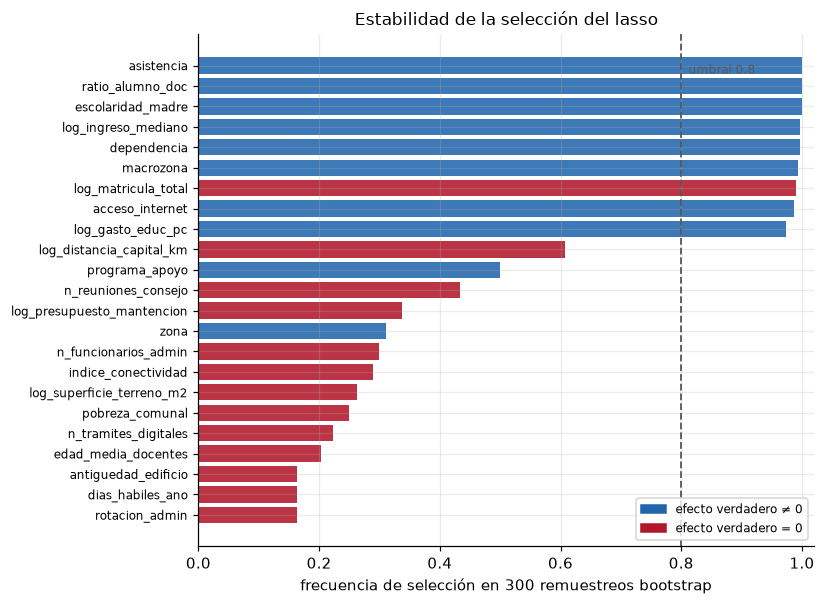

variables estables (frecuencia ≥ 0.8)
['asistencia', 'ratio_alumno_doc', 'escolaridad_madre', 'log_ingreso_mediano', 'dependencia', 'macrozona', 'log_matricula_total', 'acceso_internet', 'log_gasto_educ_pc']

zona intermedia (0.3 ≤ frecuencia < 0.8)
{'log_distancia_capital_km': 0.61, 'programa_apoyo': 0.5, 'n_reuniones_consejo': 0.43, 'log_presupuesto_mantencion': 0.34, 'zona': 0.31, 'n_funcionarios_admin': 0.3}


In [50]:
fig, ax = plt.subplots(figsize=(7.6, 5.6))
colores = ["#2166ac" if v in VERDADERAS else "#b2182b" for v in frec.index]
ax.barh(range(len(frec)), frec.values, color=colores, alpha=0.88)
ax.set_yticks(range(len(frec)), frec.index, fontsize=8)
ax.invert_yaxis()
ax.axvline(0.8, color="0.35", ls="--", lw=1.2)
ax.text(0.812, 0.4, "umbral 0.8", fontsize=8, color="0.35")
ax.set_xlim(0, 1.02)
ax.set_xlabel(f"frecuencia de selección en {B_REP} remuestreos bootstrap")
ax.set_title("Estabilidad de la selección del lasso", fontsize=11)
ax.legend(handles=[Patch(color="#2166ac", label="efecto verdadero ≠ 0"),
                   Patch(color="#b2182b", label="efecto verdadero = 0")],
          fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

print("variables estables (frecuencia ≥ 0.8)")
print(list(frec[frec >= 0.8].index))
print("\nzona intermedia (0.3 ≤ frecuencia < 0.8)")
print(frec[(frec >= 0.3) & (frec < 0.8)].round(2).to_dict())

El corte en 0.8 ordena el resultado. Arriba quedan las variables con señal verdadera, y
también `log_matricula_total`, que es estable porque estable es la relación entre tamaño y
ruralidad, no porque la matrícula cause aprendizaje. En la franja intermedia aparece
`log_distancia_capital_km`, que el ajuste único había seleccionado y que aquí se revela como
lo que es, una variable que entra o sale según el remuestreo. También caen ahí `zona` y
`programa_apoyo`, las dos verdaderas que la regla de un error estándar había omitido, lo
cual confirma que su señal existe pero es débil.

La conclusión práctica es que **una lista de variables sin una medida de reproducibilidad no
es un resultado**, y que el bootstrap cuesta unos segundos.

## 12. Desempeño fuera de muestra

La selección tiene que pagar su costo en predicción. Se comparan cinco modelos sobre el
conjunto de prueba que no se ha tocado, incluyendo un oráculo ajustado solo con las
variables verdaderas, que fija el techo alcanzable.

In [51]:
from sklearn.metrics import mean_squared_error, r2_score

def evaluar(pipe, nombre, n_activas):
    pred = pipe.predict(X_te)
    return {"modelo": nombre,
            "variables": n_activas,
            "RECM prueba": np.sqrt(mean_squared_error(y_te, pred)),
            "R2 prueba": r2_score(y_te, pred)}

vars_oraculo_num = [v for v in VARS_NUM if v in VERDADERAS]
vars_oraculo_cat = [v for v in VARS_CAT if v in VERDADERAS]
prep_or = ColumnTransformer([("num", StandardScaler(), vars_oraculo_num),
                             ("cat", OneHotEncoder(drop="first", sparse_output=False),
                              vars_oraculo_cat)])
oraculo = Pipeline([("prep", prep_or), ("modelo", LinearRegression())]).fit(X_tr, y_tr)

ols_pipe = hacer_pipeline(LinearRegression()).fit(X_tr, y_tr)

tabla = pd.DataFrame([
    evaluar(ols_pipe, "mínimos cuadrados", len(todas)),
    evaluar(ridge_min, f"ridge (α={lam_r_min:.0f})", len(todas)),
    evaluar(lasso_min, f"lasso α mínimo ({lam_l_min:.3f})", len(activas(lasso_min))),
    evaluar(lasso_1se, f"lasso 1 EE ({lam_l_1se:.3f})", len(activas(lasso_1se))),
    evaluar(enet, f"elastic net (ρ={m.l1_ratio_:.2f})", len(activas(enet))),
    evaluar(oraculo, "oráculo (solo verdaderas)", len(VERDADERAS)),
]).set_index("modelo")
tabla.round(3)

,variables,RECM prueba,R2 prueba
modelo,,,
mínimos cuadrados,23,24.909,0.626
ridge (α=28),23,24.912,0.626
lasso α mínimo (0.403),16,24.973,0.624
lasso 1 EE (1.072),10,25.286,0.615
elastic net (ρ=1.00),16,24.967,0.624
oráculo (solo verdaderas),10,24.700,0.632


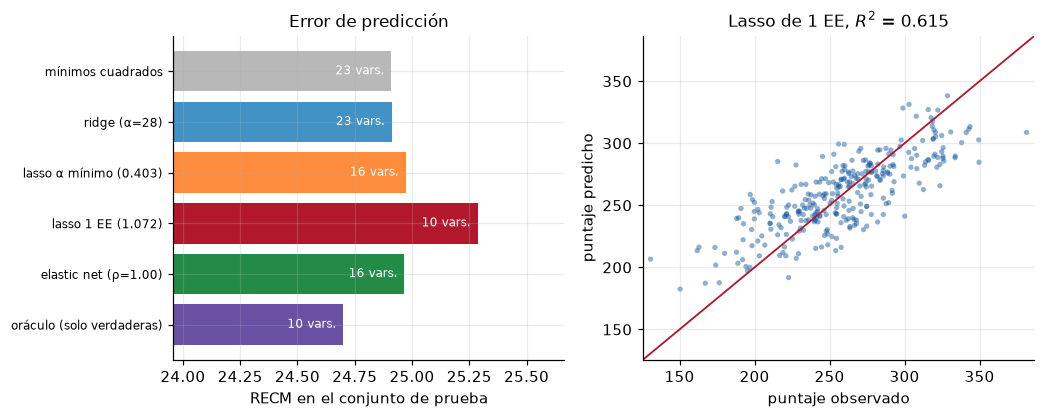

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))

ax = axes[0]
ax.barh(range(len(tabla)), tabla["RECM prueba"],
        color=["0.72", "#4292c6", "#fd8d3c", "#b2182b", "#238b45", "#6a51a3"])
ax.set_yticks(range(len(tabla)), tabla.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(tabla["RECM prueba"].min() * 0.97, tabla["RECM prueba"].max() * 1.015)
for k, (recm, nv) in enumerate(zip(tabla["RECM prueba"], tabla["variables"])):
    ax.text(recm - 0.03, k, f"{nv} vars.", ha="right", va="center",
            fontsize=8, color="white")
ax.set_xlabel("RECM en el conjunto de prueba")
ax.set_title("Error de predicción", fontsize=11)

ax = axes[1]
pred_1se = lasso_1se.predict(X_te)
ax.scatter(y_te, pred_1se, s=12, alpha=0.45, color="#08519c",
           edgecolor="none")
lim = [min(y_te.min(), pred_1se.min()) - 5, max(y_te.max(), pred_1se.max()) + 5]
ax.plot(lim, lim, color="#b2182b", lw=1.2)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("puntaje observado"); ax.set_ylabel("puntaje predicho")
ax.set_title(f"Lasso de 1 EE, $R^2$ = {r2_score(y_te, pred_1se):.3f}", fontsize=11)

fig.tight_layout(); plt.show()

El resultado es el esperado y conviene leerlo con cuidado. Las diferencias de error entre
los cinco modelos son pequeñas, de medio punto de puntaje, mientras que la diferencia
en número de variables es grande. Un modelo con menos de la mitad de las variables predice
prácticamente igual que el modelo completo, y se acerca al oráculo. **Ese es el argumento
para usar lasso en política pública**, no la ganancia predictiva, que es marginal, sino que
entrega un modelo comunicable sin perder capacidad de predicción.

## 13. Lectura para política pública

Tres advertencias que corresponde poner por escrito junto a cualquier tabla de coeficientes
regularizados.

**Los coeficientes penalizados están sesgados hacia cero por construcción.** No se deben
leer como magnitudes de efecto. Si se necesita una magnitud, el procedimiento habitual es
usar el lasso para seleccionar y luego reajustar por mínimos cuadrados sobre las variables
seleccionadas, que es el *relaxed lasso*, teniendo presente que los errores estándar de ese
segundo ajuste ignoran que la selección se hizo con los mismos datos.

**Seleccionada no significa causal.** El programa de apoyo lo muestra con claridad. Su
coeficiente verdadero es positivo, pero en los datos aparece asociado a peor puntaje porque
se focalizó en las comunas más pobres.

In [53]:
dif_bruta = (y_tr[X_tr.programa_apoyo == "Si"].mean()
             - y_tr[X_tr.programa_apoyo == "No"].mean())
j_prog = nombres.index("programa_apoyo_Si")

print(f"diferencia bruta de medias        : {dif_bruta:+6.2f} puntos")
print(f"coeficiente en el lasso de 1 EE   : {c_las[j_prog]:+6.2f}")
print(f"coeficiente en mínimos cuadrados  : {c_ols[j_prog]:+6.2f}")
sd_prog = (X_tr.programa_apoyo == "Si").to_numpy().astype(float).std()
print(f"efecto verdadero, escala estandar.: {3.5 * sd_prog:+6.2f}")

diferencia bruta de medias        : -11.57 puntos
coeficiente en el lasso de 1 EE   :  +0.00
coeficiente en mínimos cuadrados  :  +1.36
efecto verdadero, escala estandar.:  +1.72


Al condicionar en las demás variables el signo se corrige, pero eso ocurre aquí porque el
simulador puso todos los confusores en la tabla. En datos reales no hay tal garantía, y el
lasso no distingue entre un predictor útil y una causa. Para efectos causales el camino son
los diseños de identificación, y si se quiere usar regularización dentro de ellos, el
*double machine learning* de Chernozhukov y coautores, que emplea lasso para los términos de
molestia y no para el parámetro de interés.

**La estandarización condiciona el resultado.** Cambiar la escala de una variable cambia su
penalización efectiva. Por eso el escalado va dentro del `Pipeline` y por eso hay que
informar qué se estandarizó, incluidas las columnas indicadoras.

## 14. Resumen operativo

| Decisión | Qué se hizo aquí | Por qué |
|---|---|---|
| Separación de datos | 75/25 antes de mirar nada | evita que la selección vea el conjunto de prueba |
| Codificación | `OneHotEncoder(drop="first")` | evita colinealidad exacta con el intercepto |
| Escalado | `StandardScaler` sobre todas las columnas | la penalización suma entre predictores |
| Ubicación del preprocesamiento | dentro del `Pipeline` | impide fuga de información entre pliegues |
| Validación cruzada | `KFold(5, shuffle=True)` | el registro no tiene orden temporal |
| Elección de $\lambda$ | regla de un error estándar | modelo más pequeño con error equivalente |
| Métrica | ECM, y $R^2$ para informar | respuesta continua sin colas pesadas |
| Verificación | estabilidad por bootstrap | una lista sin reproducibilidad no es un hallazgo |

## 15. Ejercicios

1. Suba la desviación del error de 24 a 40 en el simulador y repita. ¿Qué variables
   verdaderas empieza a perder el lasso, y en qué orden?
2. Reemplace `KFold` por `RepeatedKFold(n_splits=5, n_repeats=5)` y compare la anchura de
   la banda de un error estándar. ¿Cambia el $\alpha$ elegido?
3. Implemente el *relaxed lasso*, esto es, reajuste por mínimos cuadrados sobre las
   variables que sobrevivieron, y compare el RECM de prueba con el de la tabla de la
   sección 12.
4. Elimine `ingreso_mediano` del conjunto de candidatas y vuelva a ajustar. ¿Recupera el
   lasso la señal socioeconómica a través de `pobreza_comunal`?
5. Codifique la dependencia administrativa con `drop=None` y ajuste ridge. Compare los
   coeficientes con los de `drop="first"` y explique por qué ridge tolera la colinealidad
   exacta que mínimos cuadrados no tolera.
6. Añada 200 columnas de ruido puro para llevar el problema a $p > N$ y observe qué le
   ocurre a la frecuencia de selección de la sección 11.